## 1. Importy

In [1]:
import urllib.request
import os
import re
import unicodedata
os.makedirs('img', exist_ok=True)
import numpy as np, torch
from collections import Counter
from torch.utils.data import Dataset, DataLoader
torch.manual_seed(0)
import matplotlib.pyplot as plt
import pandas as pd
import json


## 2. Korpus

In [2]:
url = 'https://wolnelektury.pl/media/book/txt/orwell-rok-1984.txt'
tekst = urllib.request.urlopen(url).read().decode('utf-8')
print('Długość tekstu:', len(tekst))

Długość tekstu: 567766


## 3. Oczyszczanie tekstu

In [3]:
print(repr(tekst[:600]))
print(repr(tekst[len(tekst)//2 : len(tekst)//2 + 400]))
print(repr(tekst[-1500:]))

'George Orwell\r\n\r\nRok 1984\r\ntłum. Julia Fiedorczuk\r\n\r\nISBN 978-83-288-7049-9\r\n\r\n\r\n\r\n\r\nOd tłumaczki\r\n\r\nRóżne bywają powody, dla których dokonuje się ponownego przekładu dzieła literackiego już obecnego w danym języku. Najczęściej tłumacz lub tłumaczka czują, iż istniejący przekład jest niedobry albo przestarzały i jako taki wymaga korekty. Czasem jednak chodzi o pokusę samodzielnego zmierzenia się z jakimś ważnym tekstem i przedstawienia własnej — niekoniecznie doskonalszej — interpretacji. Podjęłam się tłumaczenia Roku 1984 z tego drugiego powodu, znajdując dodatkową motywację w fakcie, iż wyko'
'tywem w tym śnie, jeśli nie najważniejszym, był zapamiętany gest matki. Ujrzał go ponownie trzydzieści lat później podczas kroniki filmowej, kiedy żydowska kobieta próbowała ochronić ramionami swojego synka na chwilę przed tym, jak ostrzał z helikoptera rozerwał oboje na strzępy.\r\n\r\n— Wiesz, do tej pory wierzyłem, że zamordowałem matkę.\r\n\r\n— Dlaczego ją zamordow

## Obcięcie przedmowy i stopki Wolnych Lektur

In [4]:
tekst_raw = tekst

start = tekst_raw.find("Był jasny, zimny kwietniowy dzień")
koniec = tekst_raw.find("-----\r\nTa lektura")
print(start, koniec)

stopka = tekst_raw[koniec:koniec+1500]
print(stopka)

tekst = tekst_raw[start:koniec].rstrip()
print(repr(tekst[:200]))
print(repr(tekst[-200:]))
print(len(tekst_raw), '->', len(tekst))

1537 564288
-----
Ta lektura, podobnie jak tysiące innych, dostępna jest na stronie wolnelektury.pl.
Wersja lektury w opracowaniu merytorycznym i krytycznym (przypisy i motywy) dostępna jest na stronie https://wolnelektury.pl/katalog/lektura/orwell-rok-1984.

Utwór opracowany został w ramach projektu Wolne Lektury przez fundację Wolne Lektury.

Wszystkie zasoby Wolnych Lektur możesz swobodnie wykorzystywać, publikować i rozpowszechniać pod warunkiem zachowania warunków licencji i zgodnie z Zasadami wykorzystania Wolnych Lektur.
Ten utwór jest udostępniony na licencji Licencja Wolnej Sztuki 1.3.: https://artlibre.org/licence/lal/pl/
Wszystkie materiały dodatkowe (przypisy, motywy literackie) są udostępnione na Licencji Wolnej Sztuki 1.3: https://artlibre.org/licence/lal/pl/
Fundacja Wolne Lektury zastrzega sobie prawa do wydania krytycznego zgodnie z art. Art.99(2) Ustawy o prawach autorskich i prawach pokrewnych.
Wykorzystując zasoby z Wolnych Lektur, należy pamiętać o zapisach licencj

### Kontrola znaków

In [5]:
cnt = Counter(tekst)
print(len(cnt))
print(sorted(cnt.items(), key=lambda x: x[1])[:25])   # najrzadsze znaki

102
[('â', 1), ('x', 1), ('Ę', 1), ('+', 1), ('=', 1), ('À', 2), ('é', 2), ('Y', 2), ('–', 5), ('%', 6), ('X', 6), ('̇', 6), ('Ó', 7), ('Ć', 7), ('7', 11), ('H', 12), ('v', 13), ('Ł', 14), ('6', 14), ('̨', 14), ('́', 15), ('5', 20), ('8', 23), ('2', 26), ('4', 28)]


In [ ]:
przed = len(set(tekst))
tekst_nfc = unicodedata.normalize('NFC', tekst)
print(len(tekst), '->', len(tekst_nfc))
print(przed, '->', len(set(tekst_nfc)))

print(set(tekst) - set(tekst_nfc))
print(set(tekst_nfc) - set(tekst))

562741 -> 562706
102 -> 99
{'̨', '̇', '́'}
set()


In [7]:
tekst = tekst_nfc
print(repr(''.join(sorted(set(tekst)))))

for z in ['\r', '\n', '*', '„', '”', '"', '—', '–', '…']:
    print(repr(z), tekst.count(z))

"\n\r !%'()*+,-.0123456789:;=?ABCDEFGHIJKLMNOPRSTUWXYZabcdefghijklmnoprstuvwxyzÀÓâéóąĆćĘęŁłńŚśźŻż–—”„…"
'\r' 2898
'\n' 2898
'*' 552
'„' 224
'”' 224
'"' 0
'—' 1738
'–' 5
'…' 82


## Czyszczenie: nowe linie, gwiazdki, puste linie

In [8]:
tekst = tekst.replace('\r\n', '\n')
tekst = tekst.replace('*', '')

print('Miejsc z 3+ enterami:', len(re.findall(r'\n{3,}', tekst)))
tekst = re.sub(r'\n{3,}', '\n\n', tekst)

for m in re.finditer('–', tekst):
    i = m.start()
    print(repr(tekst[i-30:i+30]))

print('Długość:', len(tekst))
print('Rozmiar słownika:', len(set(tekst)))
print('Ma \\r?', '\r' in tekst)
print(repr(tekst[:300]))

Miejsc z 3+ enterami: 74
'rzynajmniej go wystraszyłam!\n\n–- Szczury! — szepnął Winston.'
'm było nieco więcej uczucia:\n\n–- Czy rozumiecie, że nawet je'
'zie kapitalizmu, w latach 1920–1940. W wielu krajach pozwolo'
'ła i której nie mogła zabić.\n\n–- Pamiętasz — zapytał — tego '
'en ponownie się uśmiechnął.\n\n-– Zdradziła cię, Winstonie. Na'
Długość: 559132
Rozmiar słownika: 97
Ma \r? False
'Był jasny, zimny kwietniowy dzień, zegary wybijały trzynastą. Winston Smith, przyciskając brodę do piersi dla osłony przed zacinającym wiatrem, wślizgnął się najszybciej, jak potrafił, przez szklane drzwi Rezydencji Zwycięstwa; wirujący w podmuchach wiatru ziarnisty pył mimo wszystko dostał się do ś'


In [9]:
tekst = tekst.replace('–-', '—').replace('-–', '—')

print('Pozostałe –:', tekst.count('–'))   # ma być 1 (zakres lat)
print('Rozmiar słownika:', len(set(tekst)))

Pozostałe –: 1
Rozmiar słownika: 97


## 4. Podział na train / val / test

In [10]:
n = len(tekst)

def koniec_akapitu(poz):
    return tekst.find('\n\n', poz) + 2

c1 = koniec_akapitu(int(0.8 * n))
c2 = koniec_akapitu(int(0.9 * n))

train = tekst[:c1]
val   = tekst[c1:c2]
test  = tekst[c2:]

for nazwa, t in [('train', train), ('val', val), ('test', test)]:
    print(f'{nazwa:5s} znaków: {len(t):7d}  ({len(t)/n:.1%})  różnych znaków: {len(set(t))}')

znaki = sorted(set(train))
stoi = {z: i for i, z in enumerate(znaki)}
itos = {i: z for z, i in stoi.items()}
V = len(znaki)
print('Rozmiar słownika (train):', V)

for nazwa, t in [('val', val), ('test', test)]:
    obce = {z: t.count(z) for z in set(t) - set(znaki)}
    print(nazwa, 'znaki spoza słownika:', obce)

train znaków:  447326  (80.0%)  różnych znaków: 94
val   znaków:   56681  (10.1%)  różnych znaków: 76
test  znaków:   55121  (9.9%)  różnych znaków: 88
Rozmiar słownika (train): 94
val znaki spoza słownika: {'Ę': 1}
test znaki spoza słownika: {'+': 1, '=': 1}


## 5. Słownik (tylko z treningu) i obsługa unk

In [11]:
UNK_ID = len(znaki)
V_total = len(znaki) + 1

def enc(s):
    return [stoi.get(c, UNK_ID) for c in s]

def dec(ids):
    return ''.join(itos[i] if i != UNK_ID else '<unk>' for i in ids)

dane_train = np.array(enc(train), dtype=np.int64)
dane_val   = np.array(enc(val),   dtype=np.int64)
dane_test  = np.array(enc(test),  dtype=np.int64)

print('Rozmiar słownika (z <unk>):', V_total)
for nazwa, d in [('train', dane_train), ('val', dane_val), ('test', dane_test)]:
    print(nazwa, 'zakodowany kształt:', d.shape, '| liczba <unk>:', int((d == UNK_ID).sum()))

for nazwa, t, d in [('train', train, dane_train), ('val', val, dane_val), ('test', test, dane_test)]:
    oczekiwany = ''.join(c if c in stoi else '<unk>' for c in t)
    print(nazwa, 'dekodowanie OK:', dec(d.tolist()) == oczekiwany)

Rozmiar słownika (z <unk>): 95
train zakodowany kształt: (447326,) | liczba <unk>: 0
val zakodowany kształt: (56681,) | liczba <unk>: 1
test zakodowany kształt: (55121,) | liczba <unk>: 2
train dekodowanie OK: True
val dekodowanie OK: True
test dekodowanie OK: True


## 6. Dataset, DataLoader i kontrola batchy

In [12]:
class DatasetZnakowy(Dataset):
    def __init__(self, dane, sekw):
        self.dane, self.sekw = dane, sekw
    def __len__(self):
        return max(0, len(self.dane) - self.sekw)
    def __getitem__(self, i):
        x = self.dane[i : i + self.sekw]
        y = self.dane[i + 1 : i + self.sekw + 1]
        return torch.tensor(x), torch.tensor(y)

SEKW, BATCH = 40, 32

zbiory = {'train': (train, dane_train), 'val': (val, dane_val), 'test': (test, dane_test)}
ds, dl = {}, {}
for nazwa, (t, d) in zbiory.items():
    ds[nazwa] = DatasetZnakowy(d, SEKW)
    dl[nazwa] = DataLoader(ds[nazwa], batch_size=BATCH,
                           shuffle=(nazwa == 'train'),
                           drop_last=(nazwa == 'train'))
    print(f'{nazwa}: par={len(ds[nazwa])}, batchy={len(dl[nazwa])}')

for nazwa, (t, d) in zbiory.items():
    xb, yb = next(iter(dl[nazwa]))
    print(f'\n[{nazwa}] X:', tuple(xb.shape), 'Y:', tuple(yb.shape),
          '| typ:', xb.dtype, '| zakres ID:', int(xb.min()), '-', int(xb.max()))
    assert xb.max() < V_total and yb.max() < V_total and xb.min() >= 0

    i = 1000
    x, y = ds[nazwa][i]
    print('  wejście:', repr(dec(x.tolist())))
    print('  cel    :', repr(dec(y.tolist())))
    assert dec(x.tolist())[1:] == dec(y.tolist())[:-1]
    assert x.tolist() == enc(t[i : i + SEKW])
    assert y.tolist() == enc(t[i + 1 : i + SEKW + 1])
print('\nWszystkie kontrole OK')

train: par=447286, batchy=13977
val: par=56641, batchy=1771
test: par=55081, batchy=1722

[train] X: (32, 40) Y: (32, 40) | typ: torch.int64 | zakres ID: 1 - 88
  wejście: 'u dokuczało mu owrzodzenie żylne nad pra'
  cel    : ' dokuczało mu owrzodzenie żylne nad praw'

[val] X: (32, 40) Y: (32, 40) | typ: torch.int64 | zakres ID: 1 - 90
  wejście: '\n\n— Czasem tak, Winstonie. Ale czasem dw'
  cel    : '\n— Czasem tak, Winstonie. Ale czasem dwa'

[test] X: (32, 40) Y: (32, 40) | typ: torch.int64 | zakres ID: 1 - 88
  wejście: 'otem ciągnął łagodniejszym tonem:\n\n— Rob'
  cel    : 'tem ciągnął łagodniejszym tonem:\n\n— Robi'

Wszystkie kontrole OK


## 7. Wpływ długości okna SEKW

zbiór   test   train    val
SEKW                       
20     55101  447306  56661
40     55081  447286  56641
80     55041  447246  56601
160    54961  447166  56521


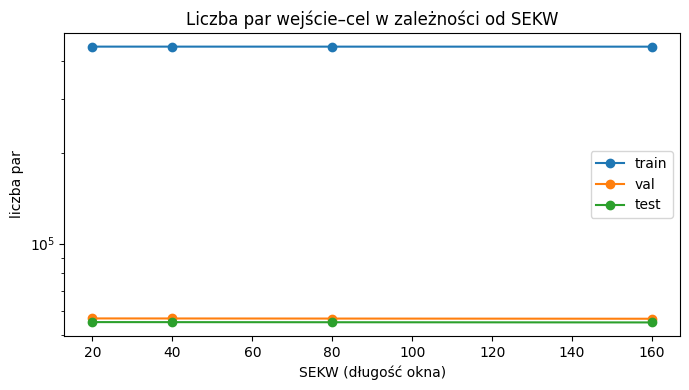

In [13]:
SEKW_LISTA = [20, 40, 80, 160]
zbiory_dane = {'train': dane_train, 'val': dane_val, 'test': dane_test}

wiersze = []
for s in SEKW_LISTA:
    for nazwa, d in zbiory_dane.items():
        pary = len(DatasetZnakowy(d, s))
        batchy = pary // BATCH if nazwa == 'train' else -(-pary // BATCH)
        wiersze.append({'SEKW': s, 'zbiór': nazwa, 'pary': pary, 'batchy': batchy})

tab = pd.DataFrame(wiersze)
print(tab.pivot(index='SEKW', columns='zbiór', values='pary'))

fig, ax = plt.subplots(figsize=(7, 4))
for nazwa in zbiory_dane:
    sub = tab[tab['zbiór'] == nazwa]
    ax.plot(sub['SEKW'], sub['pary'], marker='o', label=nazwa)
ax.set_xlabel('SEKW (długość okna)')
ax.set_ylabel('liczba par')
ax.set_yscale('log')
ax.set_title('Liczba par wejście–cel w zależności od SEKW')
ax.legend()
plt.tight_layout()
plt.savefig('img/pary_sekw.png', dpi=150)
plt.show()

## 8. Najczęstsze znaki i słowa

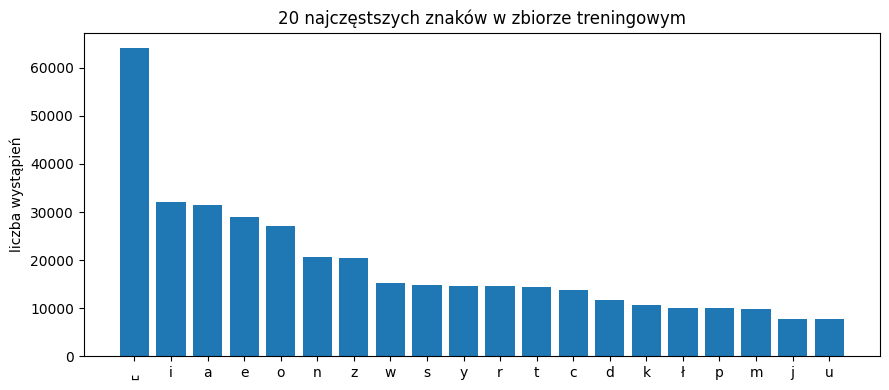

In [14]:
cnt_train = Counter(train)
top = cnt_train.most_common(20)
etykiety = [repr(z)[1:-1] for z, _ in top]   # widoczne \n, spacja jako ' '
etykiety = ['␣' if e == ' ' else e for e in etykiety]
wart = [c for _, c in top]

fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(etykiety, wart)
ax.set_title('20 najczęstszych znaków w zbiorze treningowym')
ax.set_ylabel('liczba wystąpień')
plt.tight_layout()
plt.savefig('img/znaki_top20.png', dpi=150)
plt.show()

Słów w treningu: 63979 | unikalnych: 16645
[('się', 1903), ('w', 1733), ('nie', 1405), ('i', 1258), ('na', 1061), ('z', 1025), ('to', 778), ('że', 770), ('do', 733), ('o', 527), ('winston', 394), ('po', 364), ('a', 357), ('jak', 321), ('było', 291), ('co', 277), ('tak', 275), ('od', 273), ('ale', 264), ('go', 249)]


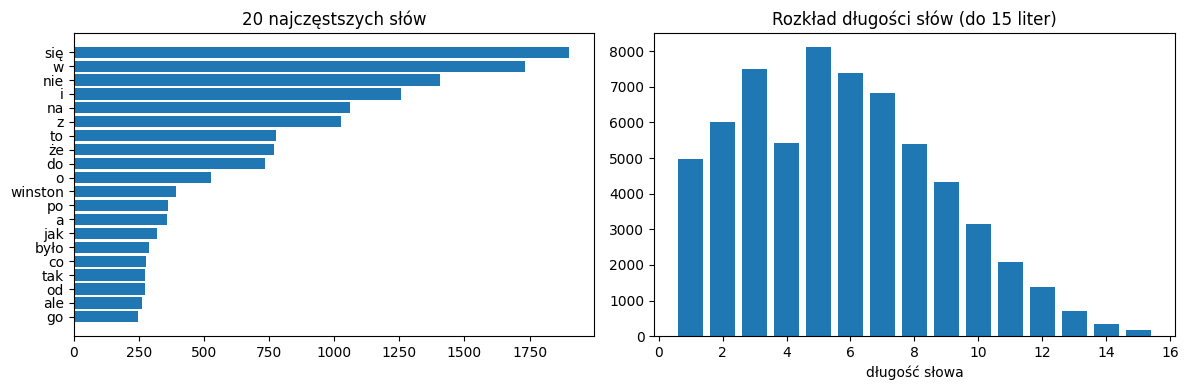

Średnia długość słowa: 5.73


In [15]:
slowa = re.findall(r'\w+', train.lower())
print('Słów w treningu:', len(slowa), '| unikalnych:', len(set(slowa)))

cnt_s = Counter(slowa)
top_s = cnt_s.most_common(20)
print(top_s)

dl_slow = Counter(len(s) for s in slowa)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].barh([s for s, _ in top_s][::-1], [c for _, c in top_s][::-1])
ax[0].set_title('20 najczęstszych słów')
ks = sorted(k for k in dl_slow if k <= 15)
ax[1].bar(ks, [dl_slow[k] for k in ks])
ax[1].set_title('Rozkład długości słów (do 15 liter)')
ax[1].set_xlabel('długość słowa')
plt.tight_layout()
plt.savefig('img/slowa.png', dpi=150)
plt.show()
print('Średnia długość słowa:', round(sum(len(s) for s in slowa) / len(slowa), 2))

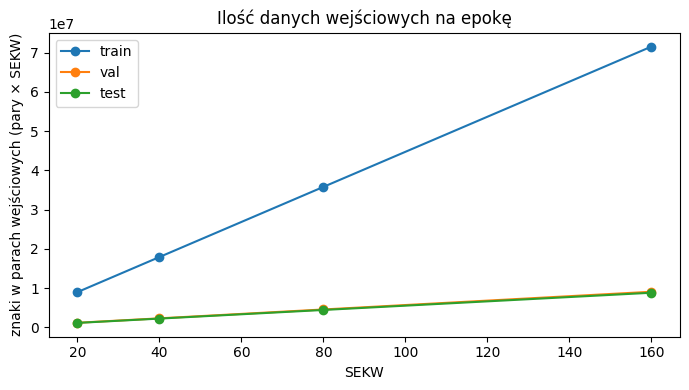

In [16]:
tab['znaki_na_epoke'] = tab['pary'] * tab['SEKW']

fig, ax = plt.subplots(figsize=(7, 4))
for nazwa in zbiory_dane:
    sub = tab[tab['zbiór'] == nazwa]
    ax.plot(sub['SEKW'], sub['znaki_na_epoke'], marker='o', label=nazwa)
ax.set_xlabel('SEKW')
ax.set_ylabel('znaki w parach wejściowych (pary × SEKW)')
ax.set_title('Ilość danych wejściowych na epokę')
ax.legend()
plt.tight_layout()
plt.savefig('img/znaki_na_epoke.png', dpi=150)
plt.show()

## 9. Zapis danych do json

In [17]:
with open('slownik.json', 'w', encoding='utf-8') as f:
    json.dump({'znaki': znaki, 'unk_id': UNK_ID, 'V_total': V_total,
               'SEKW_lista': SEKW_LISTA, 'batch': BATCH},
              f, ensure_ascii=False, indent=1)

np.savez('dane_char_rnn.npz', train=dane_train, val=dane_val, test=dane_test)

for nazwa, t in [('train', train), ('val', val), ('test', test)]:
    with open(f'{nazwa}.txt', 'w', encoding='utf-8', newline='') as f:
        f.write(t)

print('Spacja w treningu:', cnt_train[' '])

Spacja w treningu: 64056
